# Feature Extraction and Visualization with PyTorch and t-SNE


## Introduction

In this notebook, we'll explore how to extract meaningful features from images using a pre-trained deep learning model in PyTorch, and then visualize these high-dimensional features in a 2D space using t-SNE (t-Distributed Stochastic Neighbor Embedding).

### What is Feature Extraction?

Feature extraction is the process of transforming raw data (like images) into a set of features that capture the essential characteristics of the data. In deep learning, convolutional neural networks (CNNs) learn hierarchical features:
- Early layers capture low-level features like edges and textures
- Middle layers capture more complex patterns and shapes
- Later layers capture high-level, semantic concepts


### What is t-SNE?

t-SNE is a dimensionality reduction technique particularly well-suited for visualizing high-dimensional data. It works by:
1. Converting high-dimensional Euclidean distances between datapoints into conditional probabilities
2. Creating a similar probability distribution in the low-dimensional space
3. Minimizing the difference between these distributions

Unlike PCA, t-SNE is non-linear and preserves local structure, making it excellent for visualizing clusters in data.

## Setup

Let's import the necessary libraries and set up our environment:

In [1]:
!pip install -U scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 58.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [scikit-learn] [scikit-learn]


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet50, ResNet50_Weights
from sklearn.manifold import TSNE
from PIL import Image

In [3]:
# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Check if CUDA is available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## Data Loading and Preprocessing

For this tutorial, we assume you have 10 classes of images organized in folders. If you're using a standard dataset, you can adapt the code accordingly.

In [4]:
# Define image transformations
transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [5]:
# Function to load images from directories
def load_images_from_folder(folder, max_images=30):
    images = []
    labels = []
    class_names = []
    
    # List all subdirectories (classes)
    class_dirs = [d for d in os.listdir(folder) if os.path.isdir(os.path.join(folder, d))]
    
    for class_idx, class_dir in enumerate(class_dirs):
        class_path = os.path.join(folder, class_dir)
        class_names.append(class_dir)
        
        # Get image files
        files = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        
        # Limit the number of images per class
        if len(files) > max_images:
            files = np.random.choice(files, max_images, replace=False)
        
        print(f"Loading {len(files)} images from class '{class_dir}'")
        
        for file in files:
            img_path = os.path.join(class_path, file)
            try:
                img = Image.open(img_path).convert('RGB')
                img_tensor = transform(img)
                images.append(img_tensor)
                labels.append(class_idx)
            except Exception as e:
                print(f"Error loading {img_path}: {e}")
    
    return torch.stack(images), torch.tensor(labels), class_names

In [6]:
data_directory = './mini-dataset/'

In [7]:
# Load images
images, labels, class_names = load_images_from_folder(data_directory)
print(f"Loaded {len(images)} images across {len(class_names)} classes")
print(f"Class names: {class_names}")

Loading 30 images from class 'dragonfly'
Loading 30 images from class 'emu'
Loading 30 images from class 'lobster'
Loading 30 images from class 'helicopter'
Loading 30 images from class 'umbrella'
Loading 30 images from class 'rhino'
Loading 30 images from class 'gramophone'
Loading 30 images from class 'buddha'
Loading 30 images from class 'hedgehog'
Loading 30 images from class 'crayfish'
Loaded 300 images across 10 classes
Class names: ['dragonfly', 'emu', 'lobster', 'helicopter', 'umbrella', 'rhino', 'gramophone', 'buddha', 'hedgehog', 'crayfish']


## Visualizing Sample Images

Let's visualize a few sample images from each class:

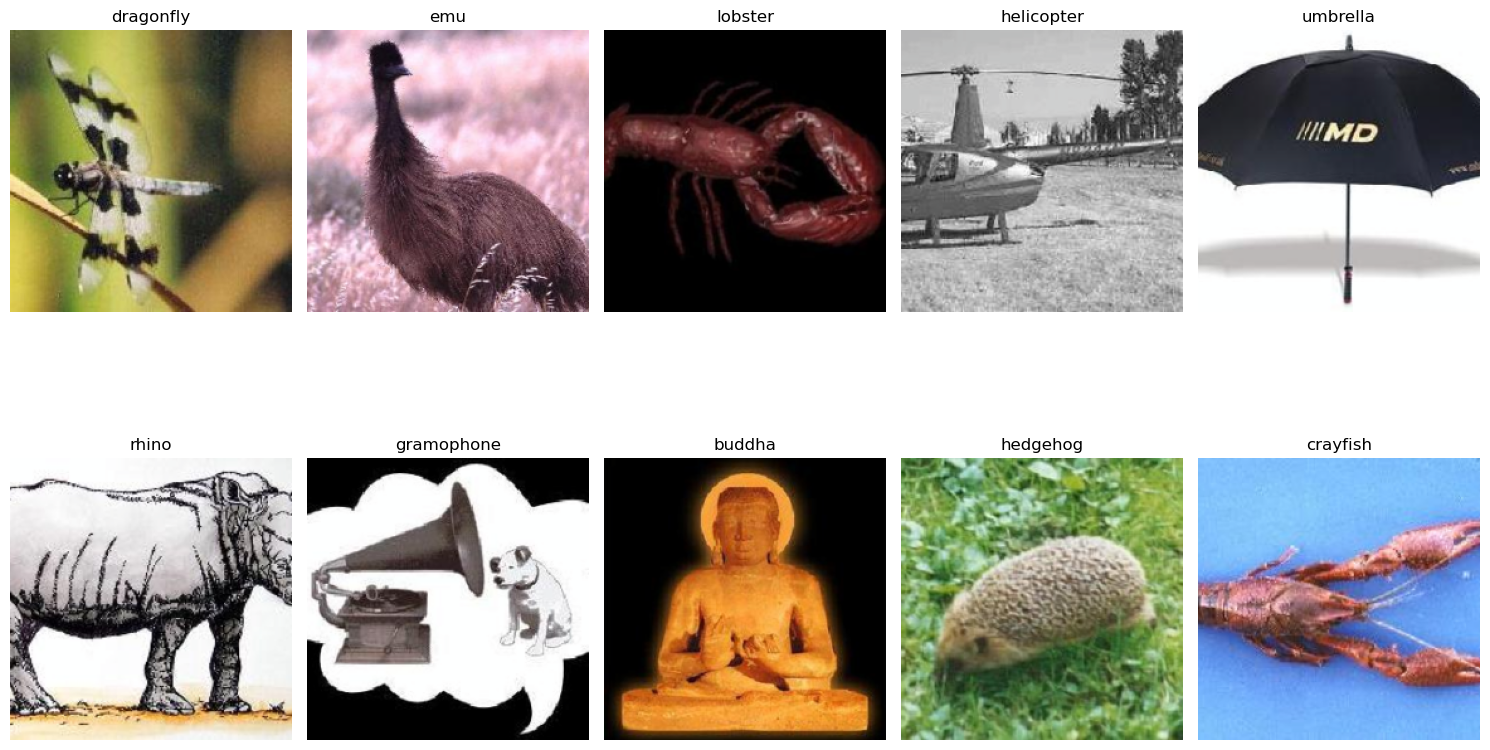

In [8]:
def imshow(img, title=None):
    img = img.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    if title is not None:
        plt.title(title)
    plt.axis('off')

# Display sample images
plt.figure(figsize=(15, 10))
for i in range(min(10, len(class_names))):
    class_indices = [j for j, label in enumerate(labels) if label == i]
    if class_indices:
        idx = np.random.choice(class_indices)
        plt.subplot(2, 5, i + 1)
        imshow(images[idx].cpu(), title=class_names[i])
plt.tight_layout()
plt.show()

## Visualizing of Transforms

Let's visualize the effects of torch transforms

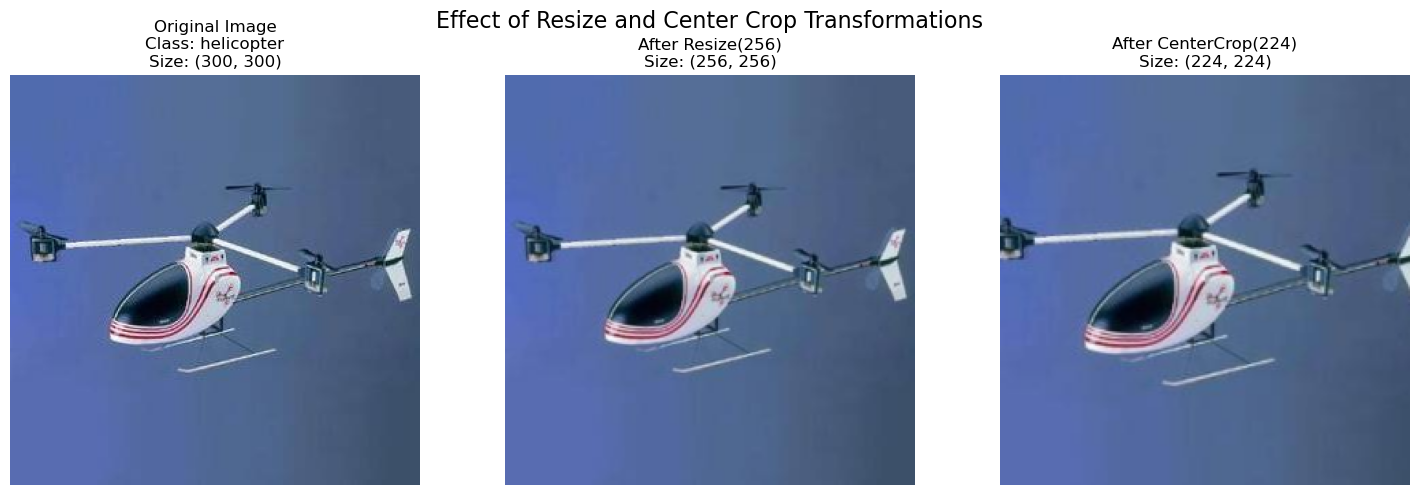

In [9]:
original_image = Image.open('mini-dataset/helicopter/image_0013.jpg')
class_name = 'helicopter'
# Apply individual transformations to visualize them
resized_image = transforms.Resize(256)(original_image)
cropped_image = transforms.CenterCrop(224)(resized_image)

# Create visualization
plt.figure(figsize=(15, 5))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(f"Original Image\nClass: {class_name}\nSize: {original_image.size}")
plt.axis('off')

# Resized image
plt.subplot(1, 3, 2)
plt.imshow(resized_image)
plt.title(f"After Resize(256)\nSize: {resized_image.size}")
plt.axis('off')

# Cropped image
plt.subplot(1, 3, 3)
plt.imshow(cropped_image)
plt.title(f"After CenterCrop(224)\nSize: {cropped_image.size}")
plt.axis('off')

plt.tight_layout()
plt.suptitle("Effect of Resize and Center Crop Transformations", fontsize=16)
plt.subplots_adjust(top=0.85)
plt.show()

## Feature Extraction with Pre-trained Model

Now, let's use a pre-trained ResNet-50 model to extract features from our images:

In [10]:
# Load pre-trained ResNet-50 model
model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
model = model.to(device)
model.eval()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████████████████████████████████████████████████████████████████████████| 97.8M/97.8M [00:01<00:00, 79.4MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [11]:
# Remove the final fully connected layer to get features
feature_extractor = torch.nn.Sequential(*list(model.children())[:-1])

In [12]:
feature_extractor

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)


In [13]:
# Extract features
features = []
batch_size=32
with torch.no_grad():  # No need to track gradients
    for i in tqdm(range(0, len(images), batch_size), desc="Extracting features"):
        batch = images[i:i+batch_size].to(device)
        batch_features = feature_extractor(batch)
        batch_features = batch_features.view(batch_features.size(0), -1)  # Flatten
        features.append(batch_features.cpu())

features = torch.cat(features, dim=0)
print(f"Extracted features shape: {features.shape}")

Extracting features: 100%|██████████████████████████████████████████████████████████████| 10/10 [00:23<00:00,  2.39s/it]

Extracted features shape: torch.Size([300, 2048])


## Dimensionality Reduction with t-SNE

Now that we have extracted high-dimensional features, let's use t-SNE to reduce them to 2 dimensions for visualization:

In [14]:
print("Applying t-SNE dimensionality reduction...")
    
# Convert to numpy for sklearn
features_np = features.numpy()

# Apply t-SNE
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42)
features_tsne = tsne.fit_transform(features_np)

print(f"t-SNE output shape: {features_tsne.shape}")

Applying t-SNE dimensionality reduction...
t-SNE output shape: (300, 2)


## Visualizing the t-SNE Results

Let's visualize the t-SNE results with different colors for each class:

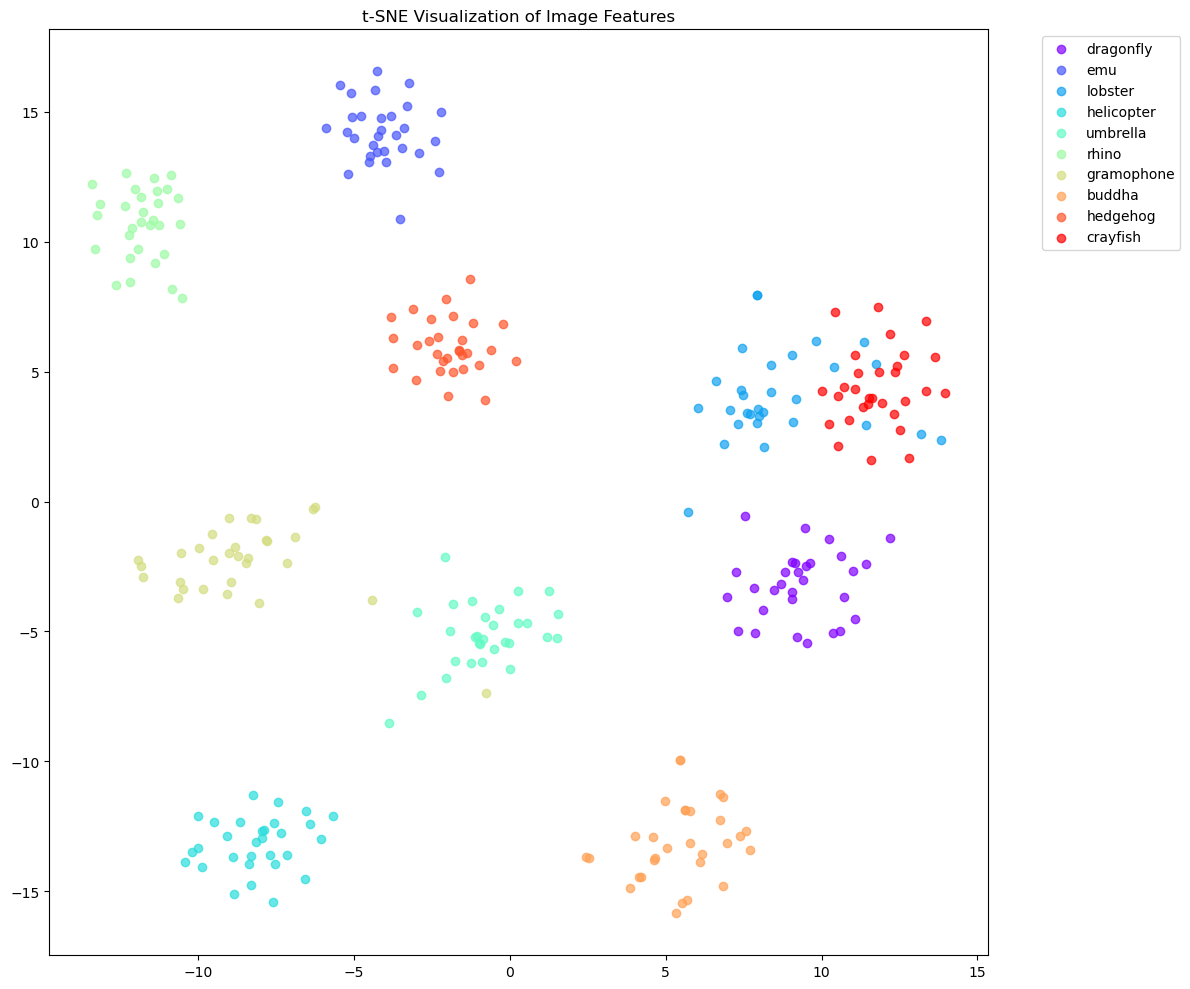

In [15]:
labels_np = labels.numpy()

# Create scatter plot
plt.figure(figsize=(12, 10))

# Colors for different classes
colors = plt.cm.rainbow(np.linspace(0, 1, len(class_names)))

# Plot each class
for i, class_name in enumerate(class_names):
    # Get indices for this class
    indices = np.where(labels_np == i)[0]
    
    # Skip if no samples for this class
    if len(indices) == 0:
        continue
    
    # Get t-SNE coordinates for this class
    x = features_tsne[indices, 0]
    y = features_tsne[indices, 1]
    
    # Plot with label
    plt.scatter(x, y, color=colors[i], label=class_name, alpha=0.7)

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('t-SNE Visualization of Image Features')
plt.tight_layout()
plt.show()

## Dimensionality Reduction with PCA

Let's use PCA to reduce them to 2 dimensions for visualization:

In [16]:

from sklearn.decomposition import PCA

# Apply PCA for dimensionality reduction
def apply_pca(features, n_components=2):
    print("Applying PCA dimensionality reduction...")
    
    # Convert to numpy for sklearn
    features_np = features.numpy()
    
    # Apply PCA
    pca = PCA(n_components=n_components, random_state=42)
    features_pca = pca.fit_transform(features_np)
    
    # Print explained variance
    explained_variance = pca.explained_variance_ratio_
    print(f"Explained variance ratio: {explained_variance}")
    print(f"Total explained variance: {sum(explained_variance):.4f}")
    
    return features_pca

# Apply PCA to our features
features_pca = apply_pca(features)
print(f"PCA output shape: {features_pca.shape}")

Applying PCA dimensionality reduction...
Explained variance ratio: [0.09209841 0.06763583]
Total explained variance: 0.1597
PCA output shape: (300, 2)


## Visualizing the PCA Results

Let's visualize the PCA results with different colors for each class:

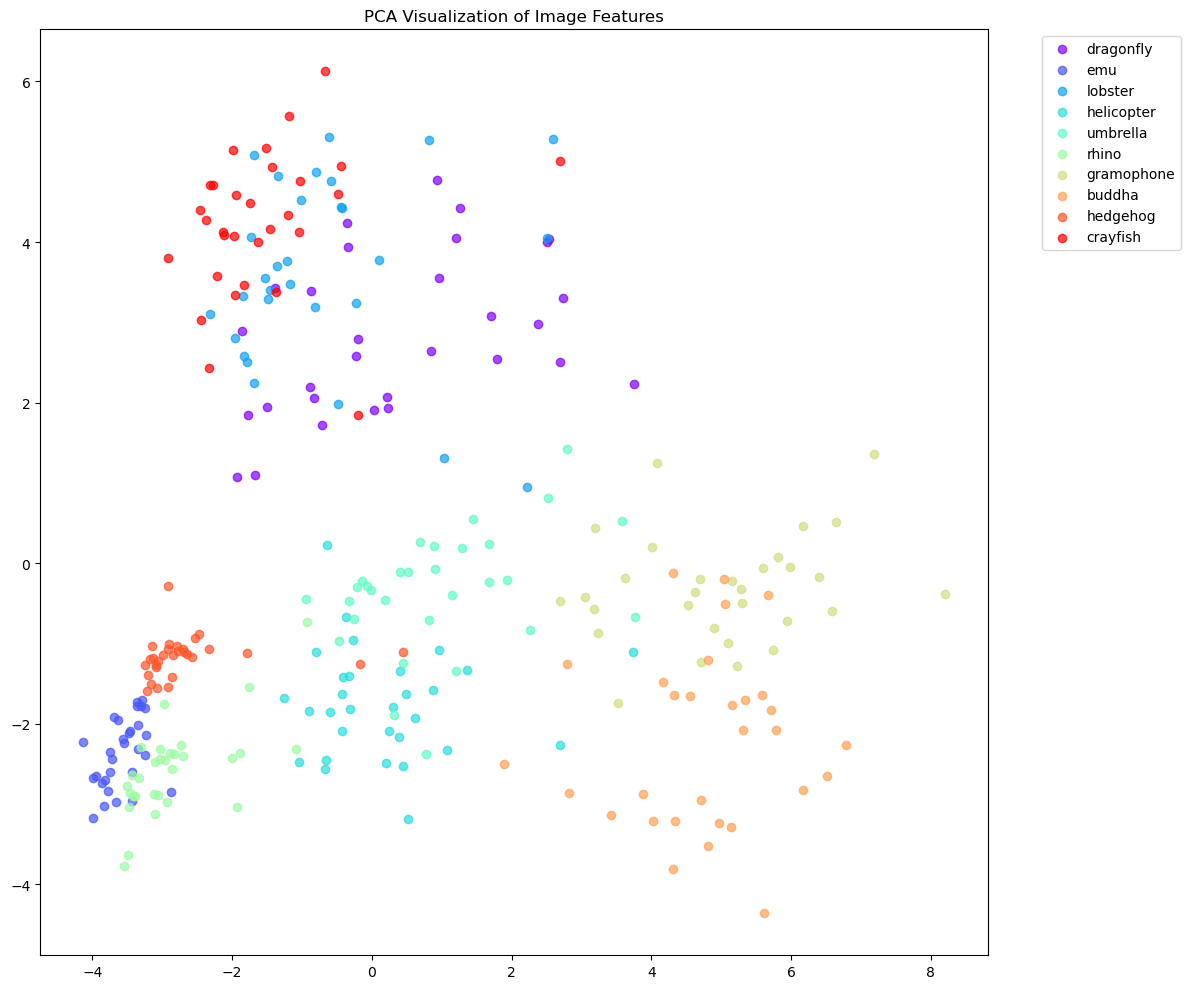

In [17]:
# Visualize PCA results
def visualize_pca(pca_results, labels, class_names):
    # Convert labels to numpy
    labels_np = labels.numpy()
    
    # Create scatter plot
    plt.figure(figsize=(12, 10))
    
    # Colors for different classes
    colors = plt.cm.rainbow(np.linspace(0, 1, len(class_names)))
    
    # Plot each class
    for i, class_name in enumerate(class_names):
        # Get indices for this class
        indices = np.where(labels_np == i)[0]
        
        # Skip if no samples for this class
        if len(indices) == 0:
            continue
        
        # Get PCA coordinates for this class
        x = pca_results[indices, 0]
        y = pca_results[indices, 1]
        
        # Plot with label
        plt.scatter(x, y, color=colors[i], label=class_name, alpha=0.7)
    
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title('PCA Visualization of Image Features')
    plt.tight_layout()
    plt.show()

# Visualize our PCA results
visualize_pca(features_pca, labels, class_names)
